# NB21: Developer Guide -- Extending RELIC

**Purpose**: Guide developers through creating new RELIC functors,
adding parameters to the database, and integrating new processes
into the simulation framework.

This is the RELIC equivalent of the WRF Developer's Guide for adding
new physics parameterizations.

## The Functor Lifecycle Chain

Every scientific module in RELIC must follow the chain:

```
Abstract Contract -> Bridge Class -> FunctorBase -> Parameter System
```

This ensures:
1. Scientific correctness (contracts)
2. System integration (bridge)
3. Lifecycle management (FunctorBase)
4. Parameter traceability (database)

**Time**: ~10 minutes


## Learning Goals

- Understand the extension path from abstract contract to bridge class, FunctorBase, and parameter system.
- Verify a developer-facing functor against local invariants before integrating it into the wider simulator.
- Connect notebook guidance back to the authoritative architecture and theory documents.


## Step 1: Choose Your Abstract Contract

All scientific modules must belong to one of the four abstract pillars:

| Pillar | Abstract Class | Bridge Class | Example |
|---|---|---|---|
| Physical Field | `PhysicalField` | `PhysicalFieldFunctor` | Radiation, turbulence |
| Biological Process | `BiologicalProcess` | `BiologicalProcessFunctor` | Photosynthesis, respiration |
| Transport Mechanism | `TransportMechanism` | `TransportMechanismFunctor` | Diffusion, advection |
| Scale Coupling | `ScaleCoupling` | `ScaleCouplingFunctor` | Patch-to-landscape |

A PhysicalField subclass declares `SPATIAL_DIMS` (1, 2, 3 or `None`);
it supplies its scientific methods rather than inheriting a default field law.
A TransportMechanism subclass declares the `TRANSPORT_TYPE` class attribute;
`transport_type=` and `diffusivity=` are not bridge constructor arguments.
Only a genuinely scalar transport coefficient uses `set_scalar_diffusivity`.
ScaleCoupling subclasses explicitly pass `source_scale`, `target_scale` and
`coupling_type`; do not restore removed generic temperature or enzyme tags.


In [1]:
import asyncio
import os
import sys
import warnings
from pathlib import Path

if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch

warnings.filterwarnings(
    "ignore",
    message="The pynvml package is deprecated.*",
    category=FutureWarning,
    module=r"torch\.cuda\.__init__",
)

DEFAULT_PROJECT_ROOT = Path(os.environ.get("RELIC_PROJECT_ROOT", Path.cwd())).resolve()


def locate_project_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd().parent.parent,
        DEFAULT_PROJECT_ROOT,
    ]
    for candidate in candidates:
        candidate = candidate.resolve()
        if (candidate / "relic").exists() and (candidate / "docs").exists():
            return candidate
    raise RuntimeError("Project root not found from current working directory")


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from relic.core.functor import BiologicalProcessFunctor
from relic.core.simulator import RELICSimulator
from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis

REFERENCE_DT_SECONDS = 1800.0


def build_farquhar_demo_state(
    ppfd: torch.Tensor | float,
    temperature: torch.Tensor | float,
    water_stress: torch.Tensor | float,
    co2_ppm: float = 410.0,
) -> dict:
    # Inputs of FarquharPhotosynthesis (metadata.input_variables); the optional input
    # vpmax_scaling is not set and defaults to vcmax_scaling in the Functor.
    ppfd_t = torch.as_tensor(ppfd, dtype=torch.float32)
    temperature_t = torch.as_tensor(temperature, dtype=torch.float32)
    water_stress_t = torch.as_tensor(water_stress, dtype=torch.float32)
    co2_t = torch.full_like(ppfd_t, float(co2_ppm))
    ones = torch.ones_like(ppfd_t)
    return {
        "air_temperature": temperature_t,                           # K
        "atmospheric_co2_ppm": co2_t,                               # umol mol-1
        "ppfd": ppfd_t,                                             # umol photons m-2 s-1
        "vcmax_scaling": ones,                                      # 1
        "jmax_scaling": ones,                                       # 1
        "water_stress_factor": water_stress_t,                      # 1
        "temperature_stress_factor": ones,                          # 1
        "ozone_stress_factor": ones,                                # 1
        "vapor_pressure_deficit": torch.full_like(ppfd_t, 1100.0),  # Pa
        "leaf_area_index": torch.full_like(ppfd_t, 3.00),           # m2 m-2
    }


def output_tensor(outputs: dict, key: str) -> torch.Tensor:
    value = outputs[key]
    return value.value if hasattr(value, "value") else value


reference_functor = FarquharPhotosynthesis(
    name="nb21_reference_farquhar",
    device=torch.device("cpu"),
    enable_gpu=False,
)
reference_state = build_farquhar_demo_state(1200.0, 298.15, 0.90)

# References:
#   Farquhar et al. (1980) Planta 149:78-90; relic/scientific/biosphere/photosynthesis/farquhar.py
# Mathematical expression:
#   A_n = FarquharPhotosynthesis.forward(state, time, dt)["net_photosynthesis"]
#   dA_n/dPPFD by automatic differentiation (torch.autograd) through the same forward()
# Parameter meanings:
#   A_n: canopy net photosynthesis; PPFD: photosynthetic photon flux density (state "ppfd")
# Units:
#   A_n [umol CO2 m-2 s-1]; PPFD [umol photons m-2 s-1]; dA_n/dPPFD [umol CO2 umol-1 photons];
#   GPP [kg C m-2 s-1]; dt [s]
# Domain/constraints:
#   forward() is the scientific kernel; calling it directly skips FunctorBase.__call__ (state
#   validation, local conservation hook, framework validation rules). The simulator always
#   calls the Functor object (NB01, NB02); a direct call is a scoped kernel diagnostic.
# Sign convention:
#   positive A_n is net CO2 uptake by the canopy.
reference_outputs = reference_functor.forward(reference_state, time=0.0, dt=REFERENCE_DT_SECONDS)

ppfd_grad = torch.tensor(1200.0, dtype=torch.float32, requires_grad=True)
grad_state = build_farquhar_demo_state(ppfd_grad, 298.15, 0.90)
grad_output = output_tensor(reference_functor.forward(grad_state, time=0.0, dt=REFERENCE_DT_SECONDS), "net_photosynthesis")
grad_output.backward()

print("=== Step 1: Inspect a Validated Reference Functor ===")
print(f"  Class: {type(reference_functor).__name__}")
print(f"  Implements BiologicalProcessFunctor: {isinstance(reference_functor, BiologicalProcessFunctor)}")
print(f"  Category: {reference_functor.metadata.category}")
print(f"  Spatial scale: {reference_functor.metadata.spatial_scale}")
print(f"  Variable kind: {reference_functor.metadata.variable_kind}")
print(f"  Execution phase: {reference_functor.metadata.execution_phase}")
print(f"  Scientific references: {len(reference_functor.metadata.references)}")
print(f"  Input count: {len(reference_functor.metadata.input_variables)}")
print(f"  Output count: {len(reference_functor.metadata.output_variables)}")
print(f"  Example net photosynthesis: {output_tensor(reference_outputs, 'net_photosynthesis').detach().item():.4f} umol CO2 m-2 s-1")
print(f"  Example mass-basis GPP: {output_tensor(reference_outputs, 'gross_primary_productivity').detach().item():.6e} kg C m-2 s-1")
print(f"  Local gradient dA_n/dPPFD: {ppfd_grad.grad.detach().item():.6f} umol CO2 umol-1 photons")
print("  [OK] Use an existing validated functor as the contract reference before extending RELIC")

=== Step 1: Inspect a Validated Reference Functor ===
  Class: FarquharPhotosynthesis
  Implements BiologicalProcessFunctor: True
  Category: ProcessCategory.BIOLOGICAL_PROCESS
  Spatial scale: SpatialScale.PATCH
  Variable kind: VariableKind.FLUX
  Execution phase: ExecutionPhase.MAIN_PROCESSES
  Scientific references: 3
  Input count: 11
  Output count: 9
  Example net photosynthesis: 16.5312 umol CO2 m-2 s-1
  Example mass-basis GPP: 2.187114e-07 kg C m-2 s-1
  Local gradient dA_n/dPPFD: 0.003612 umol CO2 umol-1 photons
  [OK] Use an existing validated functor as the contract reference before extending RELIC


## Step 2: Register with the Simulator

Register a Functor with the simulator to check its metadata and see its execution group.
`register_functor()` checks the bridge class against the metadata category, compares the
output variables with those of the registered Functors (output overlap), resolves the
execution group by the priority chain and places the Functor in the dependency graph.
`EnvironmentalForcingFunctor` declares no dependencies. A Functor whose required
dependencies are not registered yet (for example `FarquharPhotosynthesis`, whose declared
providers are printed below) is still registered, with logged warnings, unless the
simulator setting `strict_dependencies` is true; then the registration is rolled back with
`RuntimeError`.
A non-strict incomplete registration is committed but remains unpublished until
its required dependencies are present; it does not authorize execution on an
incomplete provider view.


In [2]:
# ---------------------------------------------------------------
# References:
#   RELIC registration: relic/core/simulator/registration.py
#   Environmental forcing theory: docs/source/theory/atmosphere_environmental_forcing.md
# Mathematical expression:
#   G = (V union {new_functor}, E union {new_edges})
# Parameter meanings:
#   G: dependency graph
#   V: set of functor vertices
#   E: set of dependency edges
# Units:
#   Graph membership and dependency counts [1].
# Domain/constraints:
#   A missing required provider may leave non-strict registration unpublished; no state is advanced.
# Sign convention:
#   Edges point from providers to consumers.
# ---------------------------------------------------------------

from relic.scientific.atmosphere.environmental_forcing import EnvironmentalForcingFunctor

forcing_functor = EnvironmentalForcingFunctor(
    name="nb21_environmental_forcing",
    device=torch.device("cpu"),
)

sim = RELICSimulator(config={"device": "cpu", "enable_auto_scale": True})
sim.register_functor(forcing_functor)
summary = sim.get_functor_summary()[forcing_functor.name]

print("=== Step 2: Registration Summary ===")
print(f"  Registered: {forcing_functor.name}")
print(f"  Category: {summary.get('category')}")
print(f"  Execution group: {summary.get('execution_group')}")
print(f"  Spatial scale: {summary.get('spatial_scale')}")
print(f"  Variable kind: {summary.get('variable_kind')}")
print(f"  First five inputs: {summary.get('input_variables', [])[:5]}")
print(f"  First five outputs: {summary.get('output_variables', [])[:5]}")
print(f"  Reference functor declared dependencies: {reference_functor.get_dependencies()}")
print(f"  Reference functor required inputs: {reference_functor.get_required_inputs()}")
print()
print("  [NOTE] register_functor() checked the bridge against the category, the output overlap,")
print("         the execution group and the dependency-graph placement.")
print("  [NOTE] A Functor with unregistered required providers is registered with warnings, or")
print("         rejected when strict_dependencies=True; NB01 demonstrates actual registration and stepping.")
print("         An incomplete non-strict registration remains unpublished until dependencies exist.")


=== Step 2: Registration Summary ===
  Registered: nb21_environmental_forcing
  Category: physical_field
  Execution group: fast
  Spatial scale: grid_cell
  Variable kind: forcing
  First five inputs: ['air_temperature', 'relative_humidity']
  First five outputs: ['vapor_pressure_deficit']
  Reference functor declared dependencies: ['environmental_forcing', 'atmospheric_radiation']
  Reference functor required inputs: ['air_temperature', 'atmospheric_co2_ppm', 'ppfd', 'vapor_pressure_deficit', 'leaf_area_index']

  [NOTE] register_functor() checked the bridge against the category, the output overlap,
         the execution group and the dependency-graph placement.
  [NOTE] A Functor with unregistered required providers is registered with warnings, or
         rejected when strict_dependencies=True; NB01 demonstrates actual registration and stepping.
         An incomplete non-strict registration remains unpublished until dependencies exist.


## Step 3: Add Parameters to the Database

New parameters are added to the YAML database, not hardcoded. An entry carries `value`,
`units`, `dtype`, `bounds`, `category`, `description`, `references`, `tags`,
`requires_grad` and `provenance`; the entries printed below also carry `default` and
`dimension`. The database has two tiers: `relic/parameters/database/relic` (base) and
`relic/parameters/database/calibrated` (calibration results, loaded after the base tier;
the environment variable `RELIC_SKIP_CALIBRATED=1` excludes them). For a key defined in
both, the calibrated entry is the value the ParameterManager returns. The next cell prints
two real base-tier entries and the values the global ParameterManager resolves for them.

`units`, `dtype`, `bounds` and `category` are required. Numeric values, defaults
and bound endpoints must be YAML numbers (`1.0e+7`, `1.0e-6`); numeric text is
rejected. Use `-.inf`/`.inf` for an open numeric bound and reserve `bounds: null`
for non-numeric parameters. Re-registering an unchanged shape/dtype preserves
the manager's parameter identity and live holders.

In [3]:
# ---------------------------------------------------------------
# References:
#   relic/parameters/database/relic/biosphere/photosynthesis.yaml (base-tier entries)
#   relic/parameters/database_manager.py (tier load order and precedence)
#   docs/source/architecture_overview.md, Section 6 (Parameter System)
# Mathematical expression:
#   No computation -- the cell prints database entries and resolved values
# Parameter meanings:
#   value: parameter value in `units`; bounds: valid range for optimization
#   requires_grad: whether the parameter is optimized
#   provenance.source_file: database file of the value the manager resolves
# ---------------------------------------------------------------
import yaml

from relic.parameters import get_global_manager

photosynthesis_yaml = PROJECT_ROOT / "relic" / "parameters" / "database" / "relic" / "biosphere" / "photosynthesis.yaml"
base_entries = yaml.safe_load(photosynthesis_yaml.read_text(encoding="utf-8"))["parameters"]
example_keys = ["biosphere.photosynthesis.vcmax25", "biosphere.photosynthesis.jmax25"]
example_block = {"parameters": {key: base_entries[key] for key in example_keys}}

print("=== Step 3: Parameter Database Entry ===")
print()
print(f"Base-tier entries in {photosynthesis_yaml.relative_to(PROJECT_ROOT).as_posix()}:")
print()
print(yaml.safe_dump(example_block, sort_keys=False, default_flow_style=False, width=100))

manager = get_global_manager()
print("Values the global ParameterManager resolves:")
for key in example_keys:
    spec = manager.get_parameter(key)
    source_file = Path(spec.provenance["source_file"]).resolve().relative_to(PROJECT_ROOT).as_posix()
    print(f"  {key} = {float(manager.get(key, required=True)):g} {spec.units} (source: {source_file})")
print()
print("Key rules:")
print("  1. NEVER hardcode parameter values in scientific functors")
print("  2. Use real namespace keys from the database, not ad hoc names; check that no parameter")
print("     with the same meaning exists before adding one")
print("  3. Always include value, units, dtype, bounds, category, description, references, tags,")
print("     requires_grad and provenance")
print("  4. Set requires_grad=true only for parameters intended for calibration")
print("  5. Inside functor code, access through self.get_parameter_value('name', required=True)")

=== Step 3: Parameter Database Entry ===

Base-tier entries in relic/parameters/database/relic/biosphere/photosynthesis.yaml:

parameters:
  biosphere.photosynthesis.vcmax25:
    value: 60.0
    default: 60.0
    units: umol CO2 m-2 s-1
    dtype: float32
    bounds:
    - 10.0
    - 200.0
    category: biological_parameter
    description: Maximum carboxylation rate of Rubisco at 25degC reference temperature
    references:
    - doi:10.1071/PP9900137
    - Farquhar et al. (1980) Planta 149:78-90
    tags:
    - learnable
    - calibratable
    - temperature_sensitive
    - species_specific
    dimension: molar_flux
    requires_grad: true
    provenance:
      source: literature_synthesis
      schema_version: 2.0.0
      created_by: Yuchong Long
      last_modified: '2024-01-01T00:00:00Z'
  biosphere.photosynthesis.jmax25:
    value: 120.0
    default: 120.0
    units: umol e- m-2 s-1
    dtype: float32
    bounds:
    - 20.0
    - 400.0
    category: biological_parameter
    descri

## Step 4: Testing Your Functor

Every new Functor must pass the invariant tests I1-I7 in `test/invariants/` (side effects,
units, conservation, reversibility, commutativity, dt scaling, bounds clipping). The next
cell runs three quick local checks on the kernel of the reference Functor: I1 (no side
effect on the input state), the stability of the instantaneous `net_photosynthesis` rate
when only `dt` changes, and finite outputs at two neighboring temperatures. They are
notebook checks, not the invariant test files.

In [4]:
# ---------------------------------------------------------------
# References:
#   RELIC invariant tests: test/invariants/
# Mathematical expression:
#   I1: forward(state) does not mutate state
#   dt check: instantaneous rates should be stable when dt changes but inputs stay fixed
#   finite-state check: nearby states should produce finite outputs
# Parameter meanings:
#   (see invariant definitions above)
# ---------------------------------------------------------------

state_copy = {k: v.clone() for k, v in reference_state.items()}
_ = reference_functor.forward(state_copy, time=0.0, dt=REFERENCE_DT_SECONDS)
side_effect_free = all(torch.equal(state_copy[key], reference_state[key]) for key in reference_state)

out_dt_short = output_tensor(reference_functor.forward(reference_state, time=0.0, dt=900.0), "net_photosynthesis").detach()
out_dt_long = output_tensor(reference_functor.forward(reference_state, time=0.0, dt=1800.0), "net_photosynthesis").detach()
dt_relative_difference = float(
    torch.abs(out_dt_short - out_dt_long) / torch.clamp(torch.abs(out_dt_short), min=1.0e-6)
)

cool_output = output_tensor(reference_functor.forward(
    build_farquhar_demo_state(1200.0, 294.15, 0.90),
    time=0.0,
    dt=REFERENCE_DT_SECONDS,
), "net_photosynthesis").detach()
warm_output = output_tensor(reference_functor.forward(
    build_farquhar_demo_state(1200.0, 302.15, 0.90),
    time=0.0,
    dt=REFERENCE_DT_SECONDS,
), "net_photosynthesis").detach()
finite_neighboring_states = bool(torch.isfinite(cool_output) and torch.isfinite(warm_output))

invariant_results = {
    "side_effect_free": side_effect_free,
    "dt_relative_difference": dt_relative_difference,
    "finite_neighboring_states": finite_neighboring_states,
    "cool_output": cool_output.item(),
    "warm_output": warm_output.item(),
}

print("=== Step 4: Local Verification on a Real Functor ===")
print()
print("  I1 (No Side Effects):")
print(f"    State unchanged after forward(): {side_effect_free}")
print(f"    Status: {'[OK]' if side_effect_free else '[FAIL]'}")
print()
print("  Rate stability under dt changes:")
print(f"    Output at dt=900 s:  {out_dt_short.item():.4f}")
print(f"    Output at dt=1800 s: {out_dt_long.item():.4f}")
print(f"    Relative difference: {dt_relative_difference:.6e}")
print(f"    Status: {'[OK]' if dt_relative_difference < 1.0e-6 else '[CHECK]'}")
print()
print("  Finite neighboring states:")
print(f"    Output at 294.15 K: {cool_output.item():.4f}")
print(f"    Output at 302.15 K: {warm_output.item():.4f}")
print(f"    Status: {'[OK]' if finite_neighboring_states else '[FAIL]'}")
print()
print("  Full project-level invariant tests remain under test/invariants/")

=== Step 4: Local Verification on a Real Functor ===

  I1 (No Side Effects):
    State unchanged after forward(): True
    Status: [OK]

  Rate stability under dt changes:
    Output at dt=900 s:  16.5312
    Output at dt=1800 s: 16.5312
    Relative difference: 0.000000e+00
    Status: [OK]

  Finite neighboring states:
    Output at 294.15 K: 15.7554
    Output at 302.15 K: 15.6934
    Status: [OK]

  Full project-level invariant tests remain under test/invariants/


## Visualize Functor Response & Local Check Results

The left panel shows `net_photosynthesis` of the reference Functor (one `forward()` call on
a batch of 120 states) against the photosynthetic photon flux density `ppfd` from 0 to
1800 umol photons m-2 s-1, at air temperature 298.15 K, water stress factor 0.90 and the
other inputs of Step 1. The right panel summarizes the three local checks of Step 4.

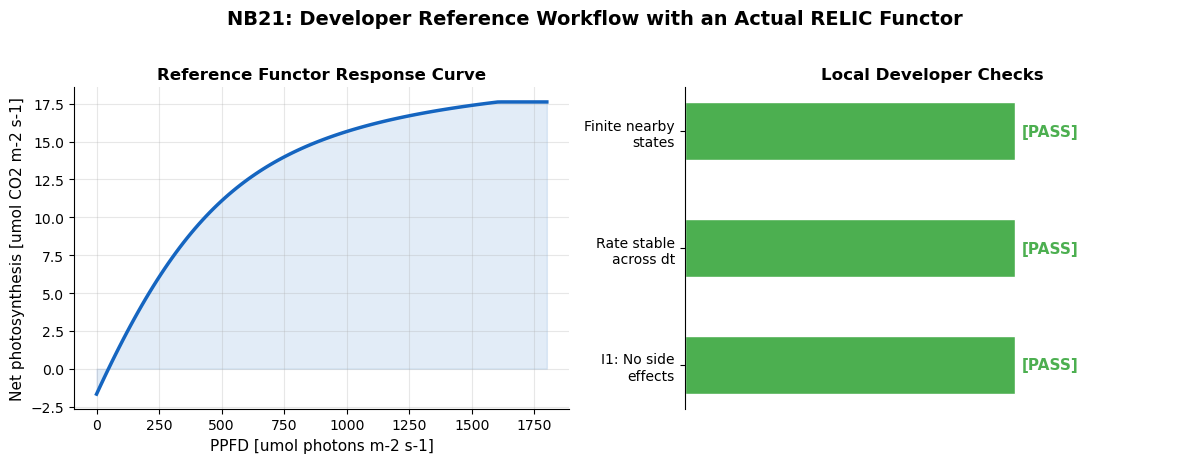

In [5]:
import matplotlib.pyplot as plt
import torch

# References:
#   RELIC invariant tests: test/invariants/
#   FarquharPhotosynthesis reference implementation in relic.scientific.biosphere.photosynthesis.farquhar
# Mathematical expression:
#   A_n(ppfd) = FarquharPhotosynthesis.forward(state(ppfd), time, dt)["net_photosynthesis"]
# Parameter meanings:
#   ppfd: photosynthetic photon flux density; net_photosynthesis: canopy net assimilation rate
#   dt_relative_difference: local diagnostic of rate stability across dt choices
# Units:
#   ppfd [umol photons m-2 s-1]; net_photosynthesis [umol CO2 m-2 s-1]; dt [s];
#   dt_relative_difference [1]
# Domain/constraints:
#   ppfd from 0 to 1800 umol photons m-2 s-1; air temperature 298.15 K; water stress factor 0.90
# Sign convention:
#   positive net_photosynthesis is net CO2 uptake; negative values are net respiration (dark)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ppfd_range = torch.linspace(0.0, 1800.0, 120)
response_state = build_farquhar_demo_state(
    ppfd=ppfd_range,
    temperature=torch.full_like(ppfd_range, 298.15),
    water_stress=torch.full_like(ppfd_range, 0.90),
)
response_curve = output_tensor(reference_functor.forward(
    response_state,
    time=0.0,
    dt=REFERENCE_DT_SECONDS,
), "net_photosynthesis").detach()

axes[0].plot(ppfd_range.tolist(), response_curve.tolist(), color="#1565C0", linewidth=2.5)
axes[0].fill_between(ppfd_range.tolist(), response_curve.tolist(), alpha=0.12, color="#1565C0")
axes[0].set_xlabel("PPFD [umol photons m-2 s-1]", fontsize=11)
axes[0].set_ylabel("Net photosynthesis [umol CO2 m-2 s-1]", fontsize=11)
axes[0].set_title("Reference Functor Response Curve", fontweight="bold", fontsize=12)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].grid(alpha=0.3)

check_names = [
    "I1: No side\neffects",
    "Rate stable\nacross dt",
    "Finite nearby\nstates",
]
check_results = [
    1 if invariant_results["side_effect_free"] else 0,
    1 if invariant_results["dt_relative_difference"] < 1.0e-6 else 0,
    1 if invariant_results["finite_neighboring_states"] else 0,
]
bar_colors = ["#4CAF50" if flag else "#f44336" for flag in check_results]
bars = axes[1].barh(check_names, check_results, color=bar_colors, edgecolor="white", height=0.5)
for idx, (bar, passed) in enumerate(zip(bars, check_results)):
    label = "[PASS]" if passed else "[CHECK]"
    axes[1].text(bar.get_width() + 0.02, idx, label, va="center", fontweight="bold", color=bar_colors[idx], fontsize=11)
axes[1].set_xlim(0, 1.5)
axes[1].set_xticks([])
axes[1].set_title("Local Developer Checks", fontweight="bold", fontsize=12)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].spines["bottom"].set_visible(False)

fig.suptitle("NB21: Developer Reference Workflow with an Actual RELIC Functor", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## RELIC Anti-Redundancy Red Lines

**Architecture Reference**: `architecture_overview.md` Section 14 (Anti-Redundancy Red Lines),
Section 4.4.2 (Device Management Policy) and Section 6 (Parameter System)

When developing custom Functors or extending RELIC, the following redundancy
patterns are **strictly forbidden**:

### Red Line 1: No Shadow Implementations

Do **not** reimplement scientific processes that already exist in `relic.scientific`.
For example, never write your own Farquhar photosynthesis or Penman-Monteith ET;
instead import and compose existing Functors.

```python
# FORBIDDEN: reimplementing photosynthesis
def my_photosynthesis(par, temp, co2):
    Vcmax = 60.0  # hardcoded!
    ...

# CORRECT: use existing Functor
from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis
photo = FarquharPhotosynthesis(name="photosynthesis")
```

### Red Line 2: No Direct CUDA Checks

Device management is centralized in `relic.core.device_policy`.
Using `torch.cuda.is_available()` anywhere outside `device_policy.py` is forbidden.

```python
# FORBIDDEN
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# CORRECT
from relic.core.device_policy import resolve_device
device = resolve_device('auto')
```

### Red Line 3: No Hardcoded Parameters

All parameters must live in YAML and be accessed through the ParameterManager.
See NB04 for the complete parameter management workflow.

```python
# FORBIDDEN
vcmax25 = 60.0  # umol CO2 m-2 s-1, hardcoded

# CORRECT (as in FarquharPhotosynthesis)
vcmax25 = self.get_parameter_value("vcmax25", namespace="biosphere.photosynthesis", required=True)
```

### Red Line 4: No Bypass of Conservation Checks

All state mutations must go through the StateManager's transactional update
mechanism. Direct dictionary mutation is forbidden.

### Red Line 5: No Multi-Version Transition Files

When refactoring, replace the old implementation entirely. Do not create
`_v2.py` or `_new.py` alongside the original.


## Summary: Developer Checklist

When adding a new scientific process to RELIC:

- [ ] Identify the correct abstract pillar (Physical/Biological/Transport/Scale)
- [ ] Subclass the appropriate bridge class
- [ ] Build a complete `FunctorMetadata` (inputs, outputs, spatial scale, variable kind,
      references, mathematical expression) and pass it to the bridge constructor; list
      optional inputs in `optional_input_variables`
- [ ] Implement `forward(state, time, dt, **kwargs)` using only differentiable tensor operations
- [ ] Add parameters to YAML database (never hardcode)
- [ ] Register with the simulator and verify dependency resolution
- [ ] Pass the invariant tests I1-I7 in `test/invariants/`
- [ ] Add scientific references in metadata and docstrings
- [ ] Create documentation in `docs/source/theory/`
- [ ] Add tests under `test/` (outside `relic/`), grouped by module and named `<module>.test.py`

**The Functor Lifecycle Chain is non-negotiable:**

```
Abstract Contract -> Bridge Class -> FunctorBase -> Parameter System
```

Any module that fails this chain will be rejected in code review.
